# Multiple Linear Regression

**Objective:** Learn multiple linear regression with simple, step-by-step examples.

## How It Works
Multiple linear regression uses more than one input feature to predict a numeric target.

## 1. Import Libraries
We start with the standard tools used in many scikit-learn examples.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

## 2. Load the Dataset
The CSV file is stored inside this topic folder so the notebook is self-contained.

In [2]:
data = pd.read_csv('datasets/student_scores.csv')
data.head()

,study_hours,practice_tests,attendance,previous_score,final_score
0,5.61,1,80.4,70.8,87.40
1,2.92,0,71.4,74.4,66.31
2,6.50,1,76.7,59.5,86.82
3,6.88,4,73.2,65.8,107.24
4,1.10,4,81.1,70.4,80.23


## 3. Explore the Data
Always inspect shape, columns, missing values, and basic statistics before modeling.

In [3]:
print(data.shape)
print(data.info())
data.describe()

(160, 5)
<class 'pandas.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   study_hours     160 non-null    float64
 1   practice_tests  160 non-null    int64  
 2   attendance      160 non-null    float64
 3   previous_score  160 non-null    float64
 4   final_score     160 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 6.4 KB
None


,study_hours,practice_tests,attendance,previous_score,final_score
count,160.000000,160.000000,160.000000,160.000000,160.000000
mean,4.872625,3.443750,82.316250,67.650625,96.177312
std,1.711900,2.438545,9.962306,12.077064,17.390839
min,0.740000,0.000000,56.300000,32.400000,57.370000
25%,3.710000,1.000000,75.900000,59.850000,83.182500
50%,4.865000,3.000000,82.900000,67.250000,97.125000
75%,6.007500,6.000000,89.350000,75.100000,110.207500
max,10.000000,7.000000,100.000000,99.200000,135.910000


In [4]:
data.isna().sum()

study_hours       0
practice_tests    0
attendance        0
previous_score    0
final_score       0
dtype: int64

## 4. Prepare Features and Target
`X` contains the input columns. `y` contains the answer we want to predict.

In [5]:
X = data.drop(columns=['final_score'])
y = data['final_score']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(X_train.shape, X_test.shape)

(128, 4) (32, 4)


## 5. Train the Model
The model learns patterns from the training data.

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[5.73,3.72,0.36,0.59]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['study_hours','practice_tests','attendance','previous_score']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-13.64
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,4


## 6. Predict and Evaluate
For regression, common metrics are MAE, RMSE, and R-squared.

In [7]:
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = (mean_squared_error(y_test, predictions) ** 0.5)
r2 = r2_score(y_test, predictions)

print('MAE:', round(mae, 2))
print('RMSE:', round(rmse, 2))
print('R2:', round(r2, 2))

MAE: 6.43
RMSE: 8.09
R2: 0.72


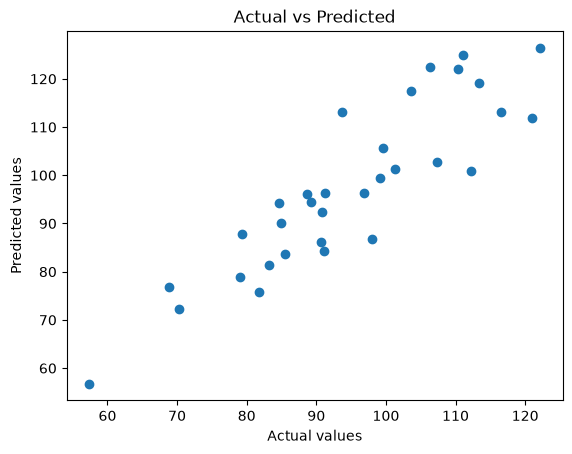

In [8]:
plt.scatter(y_test, predictions)
plt.xlabel('Actual values')
plt.ylabel('Predicted values')
plt.title('Actual vs Predicted')
plt.show()

## Try This Yourself
- Change `test_size` from `0.2` to `0.3`.
- Print the first 10 predictions.
- Add or remove one feature and compare the metrics.